In [1]:
import pandas as pd
import plotly.express as px

df = pd.read_csv('gapminder.csv')

print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 47 rows
       Country Continent  GDP_per_capita  Life_expectancy  Population  \
0  Afghanistan      Asia             550               63    38000000   
1    Australia   Oceania           54000               83    26000000   
2   Bangladesh      Asia            2200               73   170000000   
3       Brazil  Americas            8900               76   215000000   
4       Canada  Americas           46000               82    38000000   

   CO2_per_capita  
0             0.3  
1            15.1  
2             0.5  
3             2.1  
4            14.2  


In [2]:
print(df.info())
print("Continents:", df['Continent'].unique())
print(df.describe().round(1))

<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Country          47 non-null     str    
 1   Continent        47 non-null     str    
 2   GDP_per_capita   47 non-null     int64  
 3   Life_expectancy  47 non-null     int64  
 4   Population       47 non-null     int64  
 5   CO2_per_capita   47 non-null     float64
dtypes: float64(1), int64(3), str(2)
memory usage: 2.9 KB
None
Continents: <ArrowStringArray>
['Asia', 'Oceania', 'Americas', 'Africa', 'Europe']
Length: 5, dtype: str
       GDP_per_capita  Life_expectancy    Population  CO2_per_capita
count            47.0             47.0  4.700000e+01            47.0
mean          17005.5             73.7  1.397872e+08             4.6
std           20996.8              7.6  2.776975e+08             4.6
min             480.0             55.0  5.000000e+06             0.1
25%            2100.0       

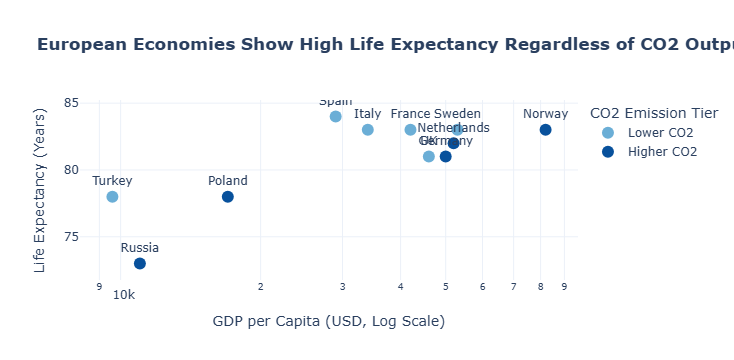

In [3]:
df_europe = df[df['Continent'] == 'Europe'].copy()

df_europe['CO2_Tier'] = pd.qcut(df_europe['CO2_per_capita'], q=2, labels=['Lower CO2', 'Higher CO2'])

fig1 = px.scatter(
    df_europe,
    x='GDP_per_capita',
    y='Life_expectancy',
    color='CO2_Tier',
    text='Country',
    log_x=True,
    title='<b>European Economies Show High Life Expectancy Regardless of CO2 Output Tier</b>',
    labels={
        'GDP_per_capita': 'GDP per Capita (USD, Log Scale)',
        'Life_expectancy': 'Life Expectancy (Years)',
        'CO2_Tier': 'CO2 Emission Tier'
    },
    color_discrete_map={'Lower CO2': '#6baed6', 'Higher CO2': '#08519c'}
)

fig1.update_traces(textposition='top center', marker=dict(size=12))
fig1.update_layout(template='plotly_white')
fig1.show()

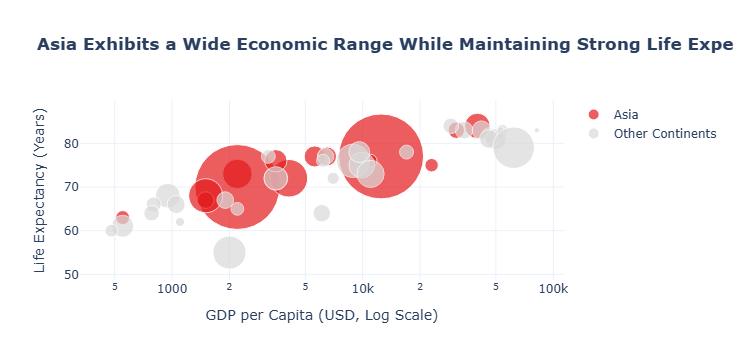

In [4]:
highlight_continent = 'Asia'
df['highlight_group'] = df['Continent'].apply(
    lambda c: highlight_continent if c == highlight_continent else 'Other Continents'
)

fig2 = px.scatter(
    df,
    x='GDP_per_capita',
    y='Life_expectancy',
    size='Population',
    color='highlight_group',
    hover_name='Country',
    log_x=True,
    size_max=60, 
    title='<b>Asia Exhibits a Wide Economic Range While Maintaining Strong Life Expectancy in Populous Nations</b>',
    labels={
        'GDP_per_capita': 'GDP per Capita (USD, Log Scale)',
        'Life_expectancy': 'Life Expectancy (Years)',
        'highlight_group': 'Region Focus'
    },
    color_discrete_map={
        'Asia': '#e41a1c',           
        'Other Continents': '#d9d9d9' 
    }
)

fig2.add_annotation(
    x=10000,
    y=72,
    text="<b>Asia:</b> Diverse economic tiers<br>with massive population scale",
    showarrow=True,
    arrowhead=2,
    arrowsize=1,
    arrowwidth=2,
    arrowcolor='#666666',
    ax=40,
    ay=-40
)

fig2.update_layout(template='plotly_white', legend_title_text='')
fig2.show()